In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap
import sklearn
import aif360

print("Responsible AI environment ready!")
print("AIF360:", aif360.__version__)
print("SHAP:", shap.__version__)
print("scikit-learn:", sklearn.__version__)

Responsible AI environment ready!
AIF360: 0.6.1
SHAP: 0.51.0
scikit-learn: 1.9.1


In [2]:
import pandas as pd
from pathlib import Path

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

url = (
    "https://archive.ics.uci.edu/ml/"
    "machine-learning-databases/adult/adult.data"
)

columns = [
    "age", "workclass", "fnlwgt", "education",
    "education_num", "marital_status", "occupation",
    "relationship", "race", "sex", "capital_gain",
    "capital_loss", "hours_per_week", "native_country",
    "income"
]

data_path = DATA_DIR / "adult.data"

if not data_path.exists():
    df = pd.read_csv(
        url,
        header=None,
        names=columns,
        skipinitialspace=True,
        na_values="?"
    )
    df.to_csv(data_path, index=False)
else:
    df = pd.read_csv(data_path)

df = df.dropna().reset_index(drop=True)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nGender distribution:")
print(df["sex"].value_counts())
print("\nIncome distribution:")
print(df["income"].value_counts())
df.head()

Dataset loaded successfully!
Dataset shape: (30162, 15)

Gender distribution:
sex
Male      20380
Female     9782
Name: count, dtype: int64

Income distribution:
income
<=50K    22654
>50K      7508
Name: count, dtype: int64


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [3]:
print("Missing values:", df.isna().sum().sum())

print("\nIncome rate by gender:")
income_rate = pd.crosstab(
    df["sex"],
    df["income"],
    normalize="index"
) * 100

display(income_rate.round(2))

print("\nPositive income rate by gender:")
print(
    df.assign(positive=(df["income"] == ">50K").astype(int))
      .groupby("sex")["positive"]
      .mean()
      .mul(100)
      .round(2)
)

Missing values: 0

Income rate by gender:


income,<=50K,>50K
sex,,
Female,88.63,11.37
Male,68.62,31.38



Positive income rate by gender:
sex
Female    11.37
Male      31.38
Name: positive, dtype: float64


In [4]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Target: 1 means income >50K
y = (df["income"] == ">50K").astype(int)

# Exclude target and gender from predictive features
X = df.drop(columns=["income", "sex"])

# Identify numeric and categorical columns
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

X_train, X_test, y_train, y_test, gender_train, gender_test = train_test_split(
    X,
    y,
    df["sex"],
    test_size=0.2,
    random_state=42,
    stratify=y
)

preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), numeric_features),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Baseline Logistic Regression")
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification report:")
print(classification_report(y_test, y_pred))


Baseline Logistic Regression
Accuracy: 0.8467

Classification report:
              precision    recall  f1-score   support

           0       0.87      0.93      0.90      4531
           1       0.74      0.60      0.66      1502

    accuracy                           0.85      6033
   macro avg       0.81      0.76      0.78      6033
weighted avg       0.84      0.85      0.84      6033



In [5]:
def fairness_metrics(y_true, y_pred, gender):
    results = pd.DataFrame({
        "gender": np.asarray(gender),
        "actual": np.asarray(y_true),
        "predicted": np.asarray(y_pred)
    })

    female = results[results["gender"] == "Female"]
    male = results[results["gender"] == "Male"]

    female_rate = female["predicted"].mean()
    male_rate = male["predicted"].mean()

    return {
        "Female positive prediction rate": female_rate,
        "Male positive prediction rate": male_rate,
        "Disparate impact (Female / Male)": (
            female_rate / male_rate if male_rate > 0 else np.nan
        ),
        "Female TPR": (
            female.loc[female["actual"] == 1, "predicted"].mean()
        ),
        "Male TPR": (
            male.loc[male["actual"] == 1, "predicted"].mean()
        ),
        "Female FPR": (
            female.loc[female["actual"] == 0, "predicted"].mean()
        ),
        "Male FPR": (
            male.loc[male["actual"] == 0, "predicted"].mean()
        )
    }

baseline_metrics = fairness_metrics(
    y_test, y_pred, gender_test
)

display(pd.Series(baseline_metrics, name="Baseline").to_frame())

,Baseline
Female positive prediction rate,0.091972
Male positive prediction rate,0.256335
Disparate impact (Female / Male),0.358795
Female TPR,0.553191
Male TPR,0.607735
Female FPR,0.029429
Male FPR,0.097212


In [6]:
from aif360.datasets import BinaryLabelDataset
from aif360.algorithms.preprocessing import Reweighing

# Prepare the training data for AIF360
train_aif = X_train.copy()
train_aif["sex"] = gender_train.to_numpy()
train_aif["income_label"] = y_train.to_numpy()

# AIF360 requires numeric columns and explicit protected attributes
train_aif["gender_binary"] = (
    train_aif["sex"] == "Male"
).astype(int)

aif_train = BinaryLabelDataset(
    df=train_aif[["income_label", "gender_binary"]],
    label_names=["income_label"],
    protected_attribute_names=["gender_binary"],
    favorable_label=1,
    unfavorable_label=0
)

# Female = unprivileged (0); Male = privileged (1)
reweighing = Reweighing(
    unprivileged_groups=[{"gender_binary": 0}],
    privileged_groups=[{"gender_binary": 1}]
)

aif_reweighted = reweighing.fit_transform(aif_train)

sample_weights = aif_reweighted.instance_weights

print("Reweighing completed.")
print("Training samples:", len(sample_weights))
print("Sample weight range:",
      round(sample_weights.min(), 4),
      "to",
      round(sample_weights.max(), 4))

pip install 'aif360[AdversarialDebiasing]'
pip install 'aif360[AdversarialDebiasing]'
pip install 'aif360[Reductions]'
pip install 'aif360[Reductions]'
pip install 'aif360[inFairness]'
pip install 'aif360[Reductions]'


Reweighing completed.
Training samples: 24129
Sample weight range: 0.7918 to 2.2178


In [7]:
# Reuse the same preprocessing and Logistic Regression pipeline
reweighted_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

reweighted_model.fit(
    X_train,
    y_train,
    classifier__sample_weight=sample_weights
)

reweighted_pred = reweighted_model.predict(X_test)

reweighted_metrics = fairness_metrics(
    y_test,
    reweighted_pred,
    gender_test
)

comparison = pd.DataFrame({
    "Baseline": baseline_metrics,
    "After Reweighing": reweighted_metrics
})

display(comparison.round(4))

print(
    "Baseline accuracy:",
    round(accuracy_score(y_test, y_pred), 4)
)
print(
    "Reweighted accuracy:",
    round(accuracy_score(y_test, reweighted_pred), 4)
)

,Baseline,After Reweighing
Female positive prediction rate,0.0920,0.1362
Male positive prediction rate,0.2563,0.2148
Disparate impact (Female / Male),0.3588,0.6341
Female TPR,0.5532,0.6766
Male TPR,0.6077,0.5367
Female FPR,0.0294,0.0629
Male FPR,0.0972,0.0690


Baseline accuracy: 0.8467
Reweighted accuracy: 0.84


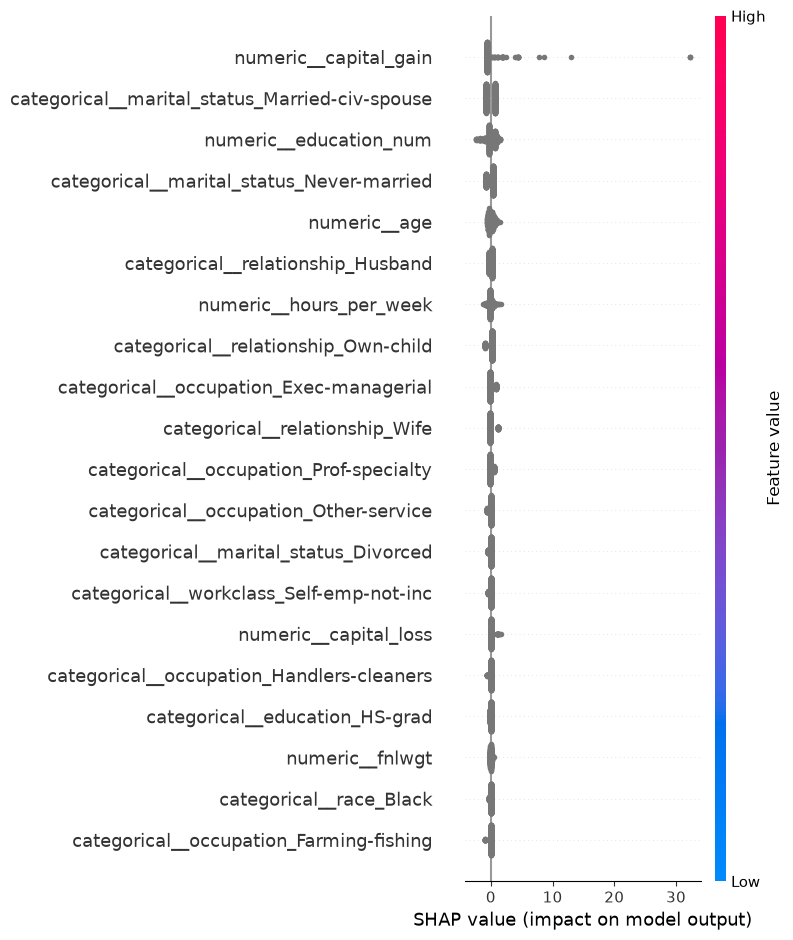

In [8]:
import shap
import matplotlib.pyplot as plt

# Transform the test data using the trained preprocessor
X_test_transformed = (
    reweighted_model.named_steps["preprocessor"]
    .transform(X_test)
)

# Get readable feature names after one-hot encoding
feature_names = (
    reweighted_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

# Explain a manageable sample for faster execution
X_explain = X_test_transformed[:500]

explainer = shap.LinearExplainer(
    reweighted_model.named_steps["classifier"],
    reweighted_model.named_steps["preprocessor"].transform(X_train[:500])
)

shap_values = explainer(X_explain)

shap.summary_plot(
    shap_values,
    X_explain,
    feature_names=feature_names,
    show=False
)

plt.tight_layout()
plt.savefig("outputs/shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
from pathlib import Path

Path("outputs").mkdir(parents=True, exist_ok=True)
print("Outputs folder ready!")

Outputs folder ready!


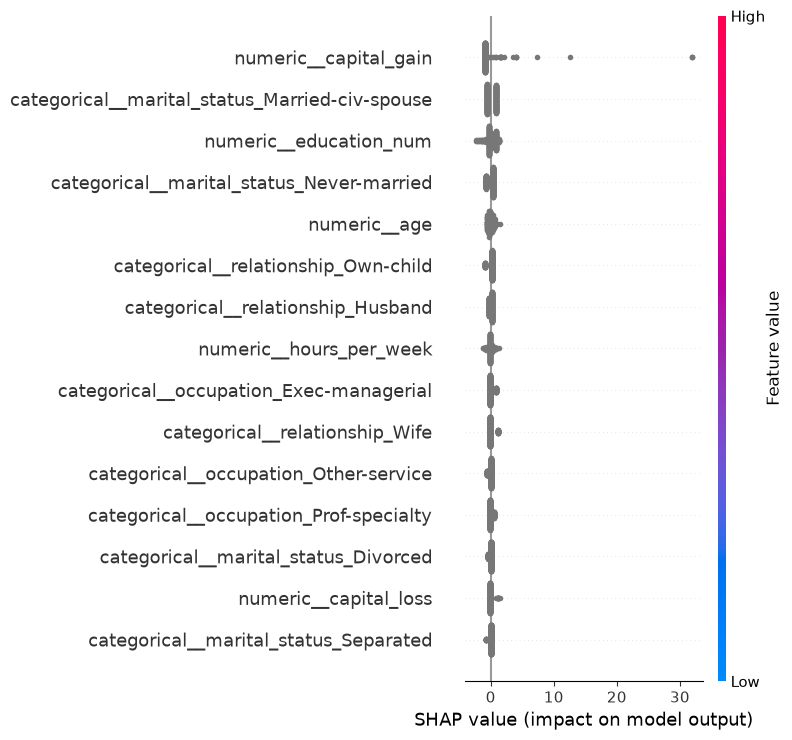

SHAP summary plot saved to outputs/shap_summary.png


In [12]:
import shap
import matplotlib.pyplot as plt
from pathlib import Path

Path("outputs").mkdir(parents=True, exist_ok=True)

# Prepare the trained model and transformed data
preprocessor_fitted = reweighted_model.named_steps["preprocessor"]
classifier_fitted = reweighted_model.named_steps["classifier"]

X_train_transformed = preprocessor_fitted.transform(X_train)
X_test_transformed = preprocessor_fitted.transform(X_test)

feature_names = preprocessor_fitted.get_feature_names_out()

# Use a small background sample to keep the explanation lightweight
background = X_train_transformed[:200]
X_explain = X_test_transformed[:300]

explainer = shap.LinearExplainer(
    classifier_fitted,
    background
)

shap_values = explainer(X_explain)

# Generate and save the SHAP summary plot
shap.summary_plot(
    shap_values,
    X_explain,
    feature_names=feature_names,
    show=False,
    max_display=15
)

plt.tight_layout()
plt.savefig(
    "outputs/shap_summary.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

print("SHAP summary plot saved to outputs/shap_summary.png")

In [13]:
from pathlib import Path

model_card = f"""
# Model Card: Adult Income Classification

## 1. Model Details
- Model: Logistic Regression
- Dataset: UCI Adult Income
- Framework: scikit-learn
- Fairness toolkit: IBM AI Fairness 360 (AIF360)
- Explainability: SHAP LinearExplainer

## 2. Intended Use
This model is for educational analysis of income classification,
fairness auditing, and explainability. It must not be used to make
real hiring, lending, insurance, or eligibility decisions.

## 3. Dataset and Factors
- Records after cleaning: {len(df):,}
- Features: demographic-independent predictors; gender excluded
  from model inputs and retained for fairness auditing.
- Female records: {(df['sex'] == 'Female').sum():,}
- Male records: {(df['sex'] == 'Male').sum():,}
- Target: income above $50K.

## 4. Performance
- Baseline accuracy: {accuracy_score(y_test, y_pred):.4f}
- Reweighted accuracy: {accuracy_score(y_test, reweighted_pred):.4f}

## 5. Fairness Analysis
- Baseline female positive prediction rate:
  {baseline_metrics['Female positive prediction rate']:.4f}
- Baseline male positive prediction rate:
  {baseline_metrics['Male positive prediction rate']:.4f}
- Baseline disparate impact:
  {baseline_metrics['Disparate impact (Female / Male)']:.4f}
- Reweighted disparate impact:
  {reweighted_metrics['Disparate impact (Female / Male)']:.4f}

The 0.80 rule is a screening guideline, not a definitive finding
of discrimination. Reweighing may improve some metrics while
affecting others.

## 6. Explainability
SHAP LinearExplainer was used to examine feature contributions.
The summary plot is saved at outputs/shap_summary.png.

## 7. Limitations and Ethical Considerations
The Adult dataset reflects historical US income patterns and is
not representative of India's population or labour market. Income
labels may reflect historical structural inequalities. Excluding
gender does not eliminate proxy discrimination through correlated
features. The model is not validated for real-world decisions.

## 8. Monitoring and Recommendations
Evaluate subgroup performance, data quality, calibration, and
fairness metrics before any deployment. Document changes and
reassess fairness over time.
"""

Path("model_card.md").write_text(model_card.strip() + "\n", encoding="utf-8")
print("Model card saved to model_card.md")

Model card saved to model_card.md


In [14]:
india_case = """
# India AI Bias Case Analysis: Facial Recognition

Facial recognition systems used in India raise concerns about
whether identification performance is consistent across demographic
groups. Research on face recognition internationally has found that
error rates can differ with skin tone, gender, image quality, and
the demographic composition of training datasets. These findings
make demographic testing important when systems are considered for
Indian public services or policing.

A potential root cause is unrepresentative training and evaluation
data. If some demographic groups are underrepresented, a model may
learn features that work better for the groups it sees most often.
Differences in cameras, lighting, image resolution, and capture
conditions can further affect performance. In deployment, these
technical limitations can create unequal risks of false matches or
failed identification.

A proposed fix is to evaluate the system on representative Indian
datasets and report false-positive and false-negative rates
separately by relevant demographic groups. Independent audits,
privacy safeguards, human review, clear appeal procedures, and
limits on high-stakes use can reduce potential harm. Developers
should document known limitations and monitor performance after
deployment.

This case illustrates why overall accuracy alone is insufficient.
Before treating a facial recognition system as reliable, an
organisation should establish that it performs acceptably across
the populations affected by its decisions. Specific claims about
any named Indian system should be supported by verifiable
published evidence.
"""

Path("india_bias_case.md").write_text(
    india_case.strip() + "\n",
    encoding="utf-8"
)

print("India bias case draft saved.")
print("Word count:", len(india_case.split()))

India bias case draft saved.
Word count: 222


In [15]:
import subprocess
import sys

subprocess.run([
    sys.executable, "-m", "nbconvert",
    "--to", "webpdf",
    "--output", "W4D6_responsible_ai",
    "W4D6_responsible_ai.ipynb"
], check=False)

CompletedProcess(args=['C:\\Users\\uzmae\\cynaris-internship-uzmaeffath\\.venv\\Scripts\\python.exe', '-m', 'nbconvert', '--to', 'webpdf', '--output', 'W4D6_responsible_ai', 'W4D6_responsible_ai.ipynb'], returncode=1)

In [16]:
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet
from reportlab.lib.enums import TA_CENTER
from reportlab.lib.units import cm
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer
)
from reportlab.lib import colors
from xml.sax.saxutils import escape
from pathlib import Path

output_pdf = Path("model_card.pdf")

doc = SimpleDocTemplate(
    str(output_pdf),
    pagesize=A4,
    rightMargin=1.6 * cm,
    leftMargin=1.6 * cm,
    topMargin=1.4 * cm,
    bottomMargin=1.4 * cm
)

styles = getSampleStyleSheet()
styles["Title"].alignment = TA_CENTER
styles["Title"].fontSize = 17
styles["Title"].leading = 20
styles["Heading2"].fontSize = 10
styles["Heading2"].leading = 12
styles["BodyText"].fontSize = 8
styles["BodyText"].leading = 10

story = [
    Paragraph("Model Card: Adult Income Classification", styles["Title"]),
    Spacer(1, 8),
    Paragraph("1. Model Details", styles["Heading2"]),
    Paragraph(
        "Logistic Regression trained on the UCI Adult Income dataset. "
        "Tools: scikit-learn, IBM AIF360 and SHAP.", styles["BodyText"]
    ),
    Paragraph("2. Intended Use", styles["Heading2"]),
    Paragraph(
        "Educational analysis of classification, fairness and explainability. "
        "Not intended for real hiring, lending, insurance or eligibility decisions.",
        styles["BodyText"]
    ),
    Paragraph("3. Data and Factors", styles["Heading2"]),
    Paragraph(
        f"Records after cleaning: {len(df):,}. Target: income above $50K. "
        "Gender was excluded from predictive inputs and retained for auditing. "
        "The dataset reflects historical US census-related income patterns.",
        styles["BodyText"]
    ),
    Paragraph("4. Performance", styles["Heading2"]),
    Paragraph(
        f"Baseline accuracy: {accuracy_score(y_test, y_pred):.4f}. "
        f"Reweighted accuracy: {accuracy_score(y_test, reweighted_pred):.4f}.",
        styles["BodyText"]
    ),
    Paragraph("5. Fairness Evaluation", styles["Heading2"]),
    Paragraph(
        f"Baseline positive prediction rates: female "
        f"{baseline_metrics['Female positive prediction rate']:.4f}; male "
        f"{baseline_metrics['Male positive prediction rate']:.4f}. "
        f"Baseline disparate impact: "
        f"{baseline_metrics['Disparate impact (Female / Male)']:.4f}. "
        f"After Reweighing: "
        f"{reweighted_metrics['Disparate impact (Female / Male)']:.4f}.",
        styles["BodyText"]
    ),
    Paragraph("6. Explainability", styles["Heading2"]),
    Paragraph(
        "SHAP LinearExplainer was used to explain feature contributions. "
        "The summary plot is saved as outputs/shap_summary.png.",
        styles["BodyText"]
    ),
    Paragraph("7. Limitations and Ethical Considerations", styles["Heading2"]),
    Paragraph(
        "The dataset is not representative of India. Historical income labels "
        "may reflect structural inequalities. Removing gender does not prevent "
        "proxy discrimination. The 0.80 disparate-impact threshold is a screening "
        "guideline, not proof of discrimination. Reweighing does not guarantee "
        "fairness across every metric or group.",
        styles["BodyText"]
    ),
    Paragraph("8. Recommendations", styles["Heading2"]),
    Paragraph(
        "Before deployment, conduct independent subgroup audits, assess data "
        "quality and predictive performance, document limitations, and monitor "
        "for changing outcomes. Do not use this educational model for consequential decisions.",
        styles["BodyText"]
    )
]

doc.build(story)

print("Model card PDF created:", output_pdf.resolve())
print("File exists:", output_pdf.exists())

Model card PDF created: C:\Users\uzmae\cynaris-internship-uzmaeffath\W4D6-responsible-ai\model_card.pdf
File exists: True


In [17]:
from pathlib import Path

for name in [
    "model_card.pdf",
    "model_card.md",
    "india_bias_case.md",
    "outputs/shap_summary.png"
]:
    path = Path(name)
    print(f"{name}: {'FOUND' if path.exists() else 'MISSING'}")

model_card.pdf: FOUND
model_card.md: FOUND
india_bias_case.md: FOUND
outputs/shap_summary.png: FOUND


In [18]:
from pathlib import Path

india_case = """
# India AI Bias Case: Facial Recognition Technology

A published study discussed by Basheer (2025) examined gender
bias in commercial facial processing tools tested on Indian faces.
The underlying audit, conducted by Jain and Parsheera, evaluated
32,184 images of electoral candidates published by the Election
Commission of India between May 2019 and November 2020. Four tools
were examined, including FaceX, developed by an Indian startup.

The reported results showed higher gender-classification error
rates for female subjects. Face++ recorded an error rate of 14.68%
for female subjects, while FaceX recorded 10.47%. The corresponding
rates for male subjects were substantially lower. These findings
illustrate why overall accuracy can hide differences between
demographic groups.

Possible root causes include limitations in training data,
algorithm design, image quality, and insufficient representation
of diverse facial characteristics. The results also show that
using locally collected images alone does not guarantee fairness.
The audit used binary gender categories, so it could not assess
performance for people outside those categories.

Proposed fixes include evaluating models on representative Indian
datasets, publishing subgroup-specific false-positive and
false-negative rates, and conducting independent audits before
deployment. Developers should also document limitations, protect
sensitive biometric information, and establish human review and
appeal procedures when system outputs affect people. High-stakes
use should be restricted unless reliability and safeguards are
demonstrated.

This case shows that responsible AI requires more than high
overall accuracy. Fairness testing must reflect the people affected
by the system and examine who experiences errors.

Source: Basheer, I. P. (2025). Bias in the Algorithm: Issues
Raised Due to Use of Facial Recognition in India. Journal of
Development Policy and Practice, 10(1), 61-79.
https://doi.org/10.1177/24551333241283992
"""

Path("india_bias_case.md").write_text(
    india_case.strip() + "\n",
    encoding="utf-8"
)

print("India bias case saved.")
print("Word count:", len(india_case.split()))

India bias case saved.
Word count: 269


In [ ]:
from pathlib import Path

files = [
    "W4D6_responsible_ai.ipynb",
    "model_card.pdf",
    "model_card.md",
    "india_bias_case.md",
    "outputs/shap_summary.png",
]

for filename in files:
    print(filename, "—", "OK" if Path(filename).exists() else "MISSING")

print("\nFairness comparison:")
display(comparison.round(4))